# Exploratory Data Analysis - AQI Dataset

## 1. Load the dataset

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_path = '../data/raw/station_day.csv'
if not os.path.exists(data_path):
    data_path = 'data/raw/station_day.csv'
features = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3',
    'CO', 'SO2', 'O3', 'Benzene', 'Toluene'
]

df = pd.read_csv(data_path)
df.head()

,StationId,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,AP001,2017-11-24,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,109.26,0.17,5.92,0.10,NaN,NaN
1,AP001,2017-11-25,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50,0.06,184.0,Moderate
2,AP001,2017-11-26,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95,0.08,197.0,Moderate
3,AP001,2017-11-27,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63,0.12,198.0,Moderate
4,AP001,2017-11-28,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02,0.07,188.0,Moderate


## 2. Basic information

In [2]:
print('Rows and columns:', df.shape)
print()
print('Column names:')
print(df.columns.tolist())

Rows and columns: (97335, 16)

Column names:
['StationId', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 97335 entries, 0 to 97334
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   StationId   97335 non-null  str    
 1   Date        97335 non-null  str    
 2   PM2.5       75636 non-null  float64
 3   PM10        56185 non-null  float64
 4   NO          80032 non-null  float64
 5   NO2         81854 non-null  float64
 6   NOx         82655 non-null  float64
 7   NH3         52258 non-null  float64
 8   CO          81011 non-null  float64
 9   SO2         72693 non-null  float64
 10  O3          73308 non-null  float64
 11  Benzene     65905 non-null  float64
 12  Toluene     60495 non-null  float64
 13  Xylene      19383 non-null  float64
 14  AQI         77414 non-null  float64
 15  AQI_Bucket  77414 non-null  str    
dtypes: float64(13), str(3)
memory usage: 13.9 MB


In [4]:
df.describe()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,75636.000000,56185.000000,80032.000000,81854.000000,82655.000000,52258.000000,81011.000000,72693.000000,73308.000000,65905.000000,60495.000000,19383.000000,77414.000000
mean,84.825523,167.467689,24.455583,37.024831,43.504385,30.328648,1.644048,12.437712,38.171303,3.461241,15.635195,2.511517,188.494872
std,78.398281,126.389213,35.478577,30.248716,46.429877,25.505255,4.492780,13.409725,40.455009,11.775976,29.494306,6.837707,134.295656
min,0.020000,0.010000,0.010000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,8.000000
25%,34.520000,75.940000,5.340000,16.220000,15.150000,13.190000,0.560000,5.010000,18.980000,0.150000,0.730000,0.000000,90.000000
50%,60.035000,132.120000,11.020000,28.960000,28.710000,25.100000,0.950000,8.970000,30.650000,1.110000,4.380000,0.330000,142.000000
75%,106.680000,223.200000,26.760000,49.250000,53.770000,39.840000,1.500000,15.110000,46.650000,3.700000,18.530000,2.000000,276.000000
max,1000.000000,1000.000000,470.000000,448.050000,467.630000,418.900000,175.810000,195.650000,963.000000,455.030000,454.850000,170.370000,2049.000000


## 3. Missing values

In [5]:
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
missing_values

Xylene        77952
NH3           45077
PM10          41150
Toluene       36840
Benzene       31430
SO2           24642
O3            24027
PM2.5         21699
AQI_Bucket    19921
AQI           19921
NO            17303
CO            16324
NO2           15481
NOx           14680
dtype: int64

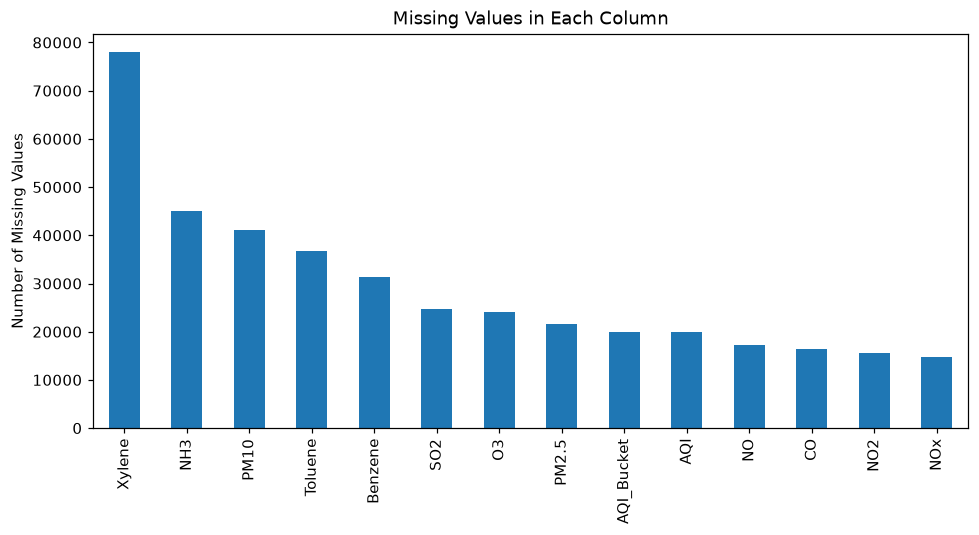

In [6]:
plt.figure(figsize=(9, 5))
missing_values.plot(kind='bar')
plt.title('Missing Values in Each Column')
plt.ylabel('Number of Missing Values')
plt.tight_layout()
plt.show()

## 4. AQI and pollutant graphs

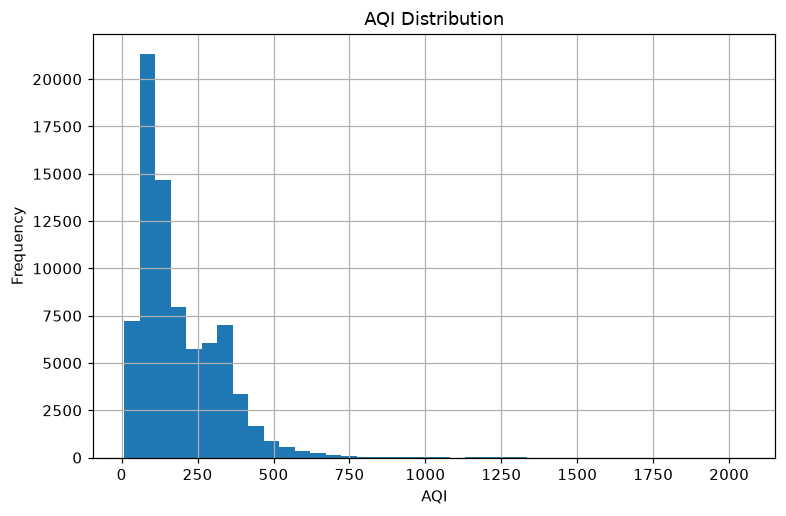

In [7]:
plt.figure(figsize=(8, 5))
df['AQI'].dropna().hist(bins=40)
plt.title('AQI Distribution')
plt.xlabel('AQI')
plt.ylabel('Frequency')
plt.show()

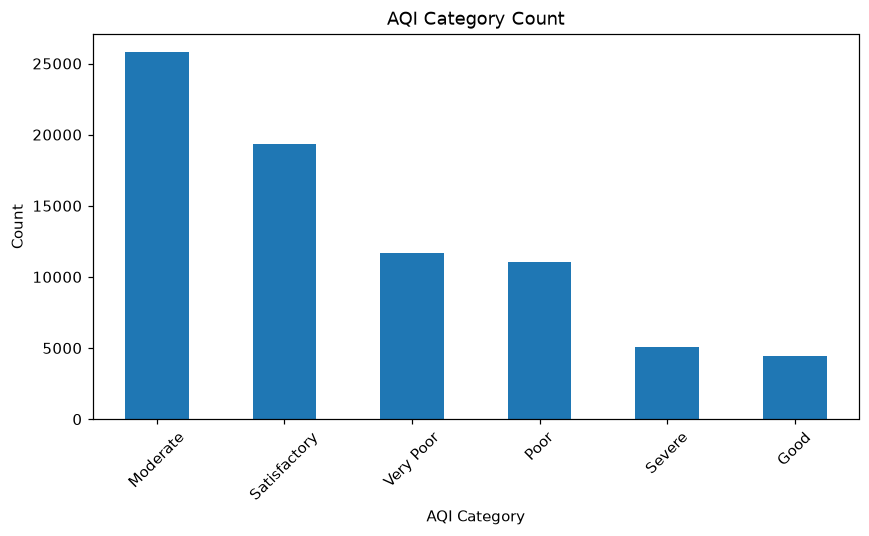

In [8]:
plt.figure(figsize=(8, 5))
df['AQI_Bucket'].value_counts().plot(kind='bar')
plt.title('AQI Category Count')
plt.xlabel('AQI Category')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

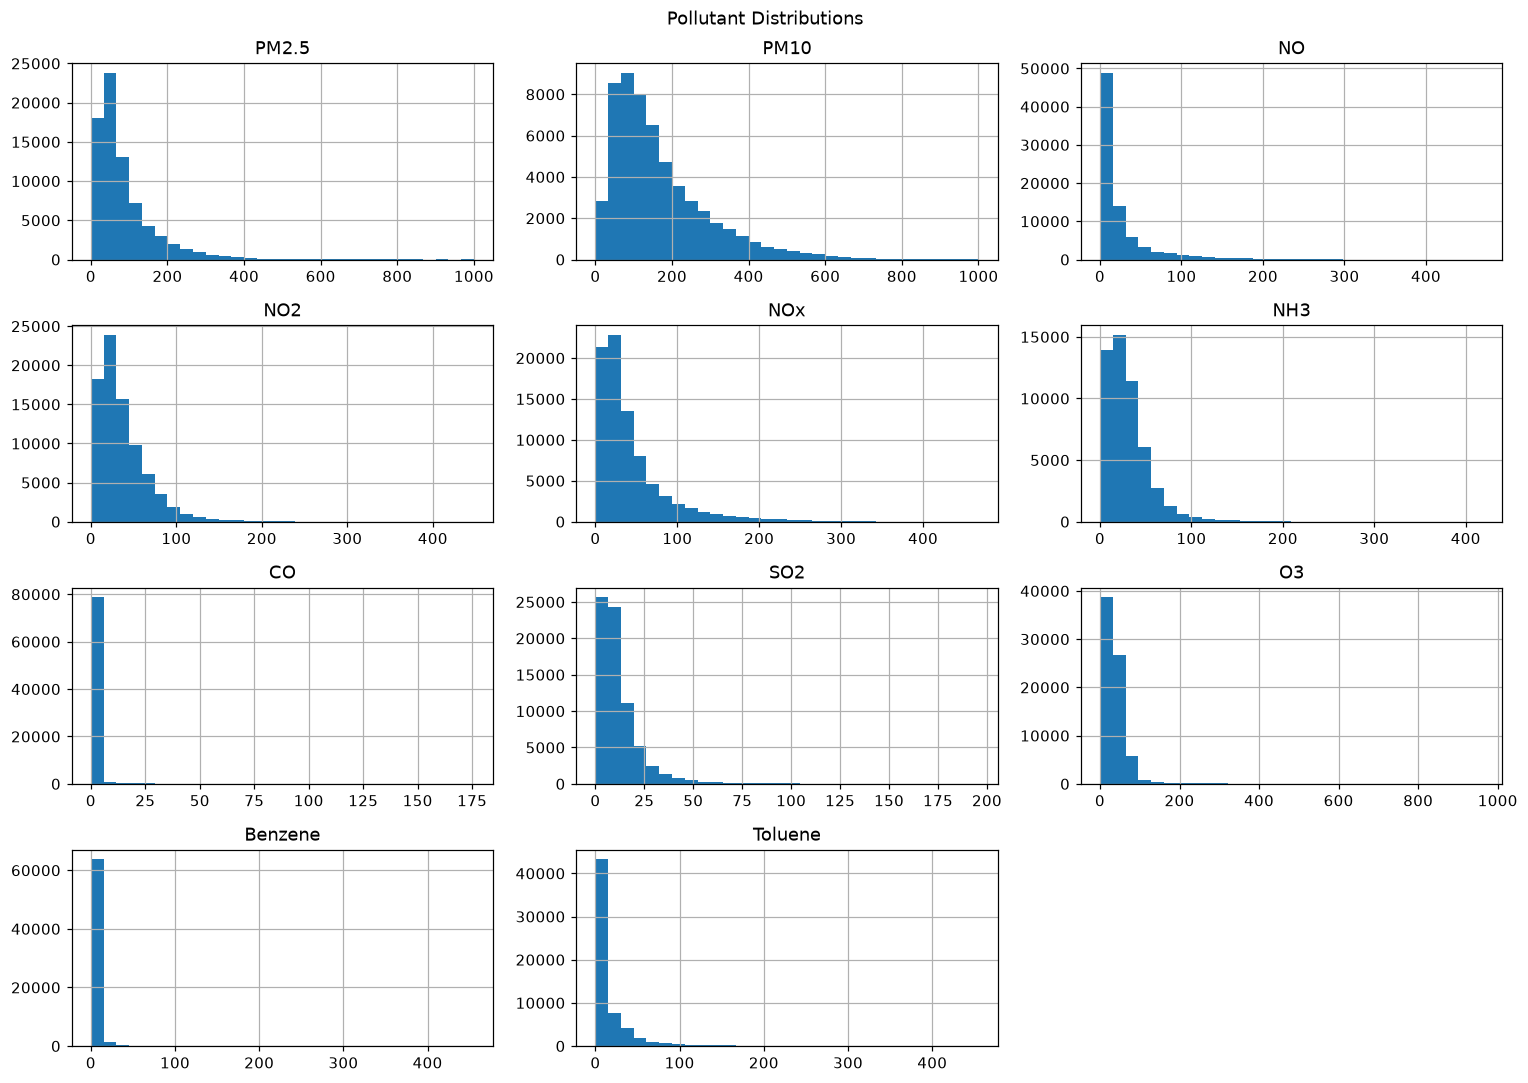

In [9]:
df[features].hist(figsize=(14, 10), bins=30)
plt.suptitle('Pollutant Distributions')
plt.tight_layout()
plt.show()

## 5. Correlation

In [10]:
correlation = df[features + ['AQI']].corr()
correlation['AQI'].sort_values(ascending=False)

AQI        1.000000
PM10       0.882168
PM2.5      0.808388
NO         0.502287
NOx        0.486232
NO2        0.481764
CO         0.457018
NH3        0.425202
SO2        0.405958
Toluene    0.280287
O3         0.155274
Benzene    0.112809
Name: AQI, dtype: float64

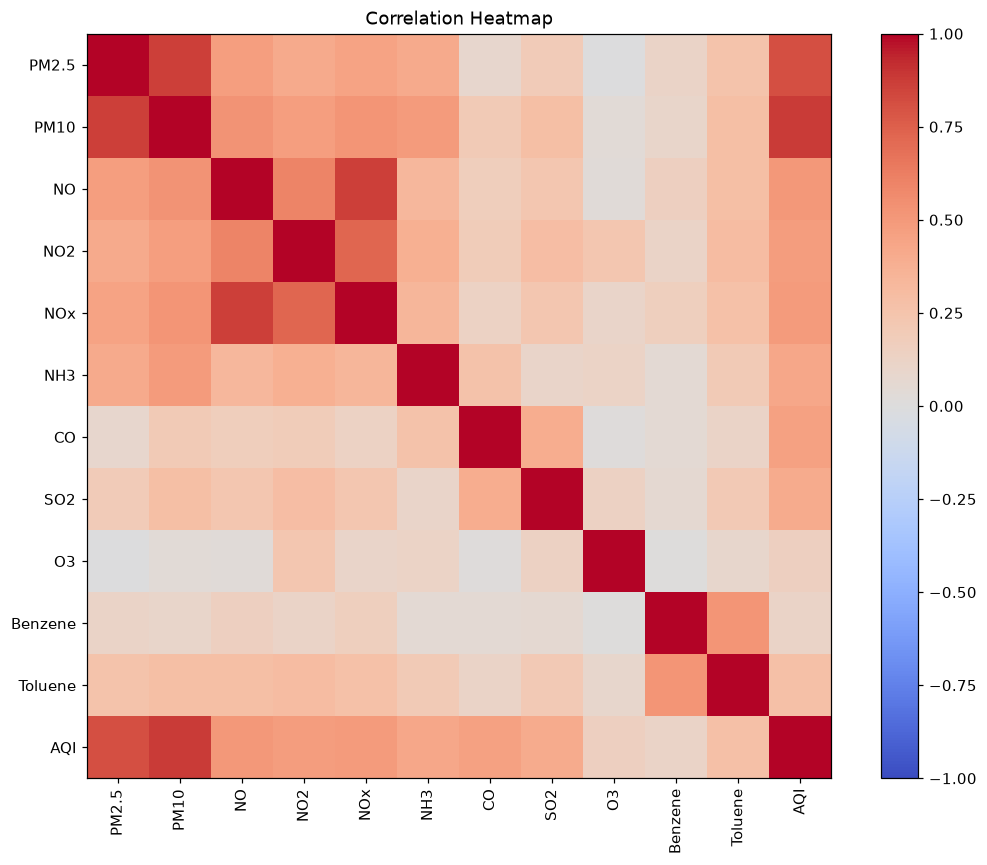

In [11]:
plt.figure(figsize=(10, 8))
plt.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

## 6. AQI change over time

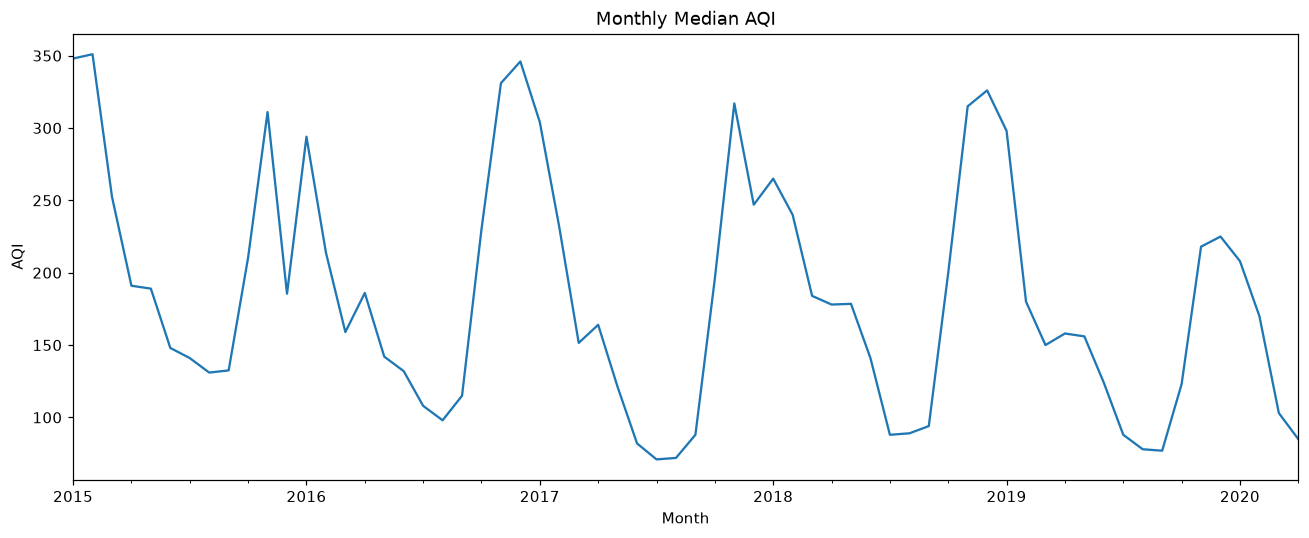

In [12]:
df['Date'] = pd.to_datetime(df['Date'])
monthly_aqi = df.groupby(df['Date'].dt.to_period('M'))['AQI'].median()

plt.figure(figsize=(12, 5))
monthly_aqi.plot()
plt.title('Monthly Median AQI')
plt.xlabel('Month')
plt.ylabel('AQI')
plt.tight_layout()
plt.show()